# Lezione 13 — Caso TakeHome
## First Republic Bank 2023 — due ondate di deposit run e vincoli di ristrutturazione del bilancio

### Prompt 1 — Inquadramento del caso

La **Scheda Caso TakeHome** costituisce la specifica vincolante e non deve essere modificata.

**Domanda quantitativa.** Come deve essere costruito il piano ALM ottimo di First Republic in presenza di una quota minima di attività legacy e come cambia al variare dell'intensità della prima ondata di deflussi, della seconda ondata e della capacità disponibile di funding?

**Driver**
- $\alpha$: fabbisogno della prima data;
- $\beta$: fabbisogno della quarta data;
- $\phi$: capacità massima di funding.

**Quantità da determinare**
- benchmark $x^*,g^*,u^*,\Pi^*$;
- residuali, slack, bounds attivi e marginali;
- sensitività ad $\alpha$, $\beta$, $\phi$;
- variazioni rispetto al benchmark e utilizzo della capacità;
- comportamento del vincolo legacy;
- confronto fra prima e seconda ondata;
- tre scenari congiunti e perdita rispetto allo Standard.

**Tabelle richieste**
1. Benchmark e diagnostica.
2. Sensitività ad $\alpha$.
3. Sensitività a $\beta$.
4. Sensitività a $\phi$.
5. Confronto degli scenari.
6. Controllo del vincolo legacy.

**Figure richieste**
1. Valore ottimo rispetto ad $\alpha$.
2. Valore ottimo rispetto a $\beta$.
3. Valore ottimo e capacità di funding rispetto a $\phi$.
4. Composizione ottima dell'attivo.
5. Utilizzo della capacità di funding.
6. Confronto tra prima e seconda ondata.

**Controlli**
- residuali, slack, bounds, prudenziale, legacy, $x_5\leq35$, funding, non negatività;
- corretta codifica di $x_3+x_4\geq35$ come $-x_3-x_4\leq-35$;
- relazione $\partial\Pi^*/\partial L=m$ senza ulteriore cambio di segno;
- $\alpha$ solo sulla prima data, $\beta$ solo sulla quarta, $\phi$ solo sui bounds;
- costo del funding invariato;
- sensitività separate prima del confronto;
- uso esclusivo di risultati validi;
- riproducibilità integrale.

## Prompt 2 — Flusso logico-teorico risolutivo
**Regime A**

| Passo | Finalità risolutiva | Formula / proprietà | Applicazione nel caso | Output o controllo |
|---:|---|---|---|---|
| 1 | Ricostruire il nuovo problema e la forma solver | PL ALM; $\max\Pi\leftrightarrow\min(-\Pi)$ | Cinque attivi, doppia ondata, legacy, limite $x_5$ | Mappa teorica e struttura solver |
| 2 | Risolvere e validare il benchmark e il legacy | Residuali, slack, vincoli attivi, dualità locale | $(1,1,1)$ e verifica $\partial\Pi^*/\partial L=m$ | Tabelle 1 e 6 |
| 3 | Costruire il solver parametrico | Termini noti e bounds parametrizzati | $\alpha,\beta,\phi$ solo dove previsto | `solve(alpha,beta,phi)` |
| 4 | Analizzare e confrontare le due ondate | Comparative statics; timing ALM | Griglie separate di $\alpha$ e $\beta$ | Tabelle 2–3; Figure 1–2,4,6 |
| 5 | Analizzare la capacità di funding | Bounds parametrizzati | Griglia $\phi$ | Tabella 4; Figure 3 e 5 |
| 6 | Confrontare i tre driver e i vincoli strutturali | Cambiamenti di regime | Timing, legacy, $x_5$, bounds | Sintesi comparativa |
| 7 | Analizzare gli scenari congiunti | Scenario analysis deterministica | Standard, Medio, Critico | Tabella 5 |
| 8 | Verificare coerenza e limiti | Coerenza modello–solver–output | Checklist e autonomia rispetto all'Aula | Base quantitativa finale |

## Prompt 3 — Scomposizione in tappe input-output
**Regime A/B**

| Tappa | Titolo | Obiettivo | Input | Operazione | Output | Controllo | Uso successivo | Regime |
|---:|---|---|---|---|---|---|---|:---:|
| 1 | Ricognizione e forma solver | Riformulare il nuovo problema | Scheda Caso | Costruire struttura e matrici | Forma solver | Autonomia, dimensioni, segni | Benchmark | A/B |
| 2 | Benchmark, legacy e solver parametrico | Validare e generalizzare | Forma solver | Solve, diagnostica, perturbazione, funzione parametrica | Tabelle 1 e 6 | $\partial\Pi^*/\partial L=m$, replica benchmark | Sensitività | A/B |
| 3 | $\alpha$, $\beta$ e confronto | Studiare le due ondate | Funzione parametrica | Due griglie separate e confronto | Tabelle 2–3; Figure 1–2,4,6 | Unico driver, timing | $\phi$ | A/B |
| 4 | $\phi$ e confronto driver | Studiare capacità e sintesi | Risultati precedenti | Griglia $\phi$ e confronto | Tabella 4; Figure 3 e 5 | $\phi$ solo bounds | Scenari | A/B |
| 5 | Scenario analysis | Variazione congiunta | Tre scenari | Solve e confronto | Tabella 5 | Standard=benchmark, parametri esatti | Chiusura | B |
| 6 | Controlli conclusivi | Validare il notebook | Tutti gli output | Checklist e limiti | Sintesi quantitativa | Completezza, riproducibilità, autonomia | Interpretazione finale | A |

# Tappa 1 — Ricognizione del nuovo problema e forma solver
**Regime A/B**

**Obiettivo.** Riconoscere ciò che deve essere riformulato rispetto al Caso Aula e costruire la nuova forma solver.

**Elementi distintivi.**
- cinque classi di attivo;
- due driver temporali distinti, $\alpha$ e $\beta$;
- vincolo legacy $x_3+x_4\geq35$;
- limite separato $x_5\leq35$;
- capacità di funding governata da $\phi$;
- costo del funding non parametrizzato.

**Vettore decisionale**
$$
z=(x_1,\ldots,x_5,g_1,\ldots,g_4,u_1,u_2,u_3)'.
$$

**Output.** Struttura solver completa.

**Controllo.** Autonomia rispetto all'Aula, dimensioni, segni, ordinamento e corretta codifica del legacy.

**Uso successivo.** Benchmark First Republic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)
TOL=1e-8

A0=100.0
c=np.array([0.008,0.022,0.035,0.045,0.050])
ell=np.array([0.000,0.015,0.060,0.100,0.120])
A_CF=np.array([
    [1.00,0.70,0.05,0.05,0.10],
    [0.00,0.30,0.10,0.15,0.20],
    [0.00,0.00,0.25,0.30,0.30],
    [0.00,0.00,0.60,0.50,0.40],
])
d0=np.array([32.0,18.0,14.0,32.0])
r_g=np.array([0.004,0.005,0.006])
r_u=np.array([0.018,0.025,0.040])
u_bar=np.array([4.0,3.0,2.0])
K=7.5
L_legacy=35.0
x5_max=35.0

names=[f"x{i}" for i in range(1,6)]+[f"g{i}" for i in range(1,5)]+[f"u{i}" for i in range(1,4)]
idx={n:i for i,n in enumerate(names)}
n=len(names)

def build_th(alpha=1.0,beta=1.0,phi=1.0,L=L_legacy):
    d=np.array([32*alpha,18.0,14.0,32*beta])
    f=np.zeros(n)
    f[:5]=-c
    f[idx["g1"]:idx["g4"]]=-r_g
    f[idx["u1"]:idx["u3"]+1]=r_u

    Aeq=[]; beq=[]
    row=np.zeros(n); row[:5]=1; Aeq.append(row); beq.append(A0)
    row=np.zeros(n); row[:5]=A_CF[0]; row[idx["u1"]]=1; row[idx["g1"]]=-1; Aeq.append(row); beq.append(d[0])
    row=np.zeros(n); row[:5]=A_CF[1]; row[idx["g1"]]=1+r_g[0]; row[idx["u1"]]=-(1+r_u[0]); row[idx["u2"]]=1; row[idx["g2"]]=-1; Aeq.append(row); beq.append(d[1])
    row=np.zeros(n); row[:5]=A_CF[2]; row[idx["g2"]]=1+r_g[1]; row[idx["u2"]]=-(1+r_u[1]); row[idx["u3"]]=1; row[idx["g3"]]=-1; Aeq.append(row); beq.append(d[2])
    row=np.zeros(n); row[:5]=A_CF[3]; row[idx["g3"]]=1+r_g[2]; row[idx["u3"]]=-(1+r_u[2]); row[idx["g4"]]=-1; Aeq.append(row); beq.append(d[3])

    Aub=[]; bub=[]
    row=np.zeros(n); row[:5]=ell; Aub.append(row); bub.append(K)
    row=np.zeros(n); row[idx["x3"]]=-1; row[idx["x4"]]=-1; Aub.append(row); bub.append(-L)
    row=np.zeros(n); row[idx["x5"]]=1; Aub.append(row); bub.append(x5_max)

    bounds=[(0,None)]*9+[(0,phi*u_bar[t]) for t in range(3)]
    return f,np.array(Aeq),np.array(beq),np.array(Aub),np.array(bub),bounds,d

f,A_eq,b_eq,A_ub,b_ub,bounds,_=build_th()
assert f.shape==(12,)
assert A_eq.shape==(5,12)
assert A_ub.shape==(3,12)
assert np.allclose(A_ub[1,[idx["x3"],idx["x4"]]],[-1,-1])
assert np.isclose(b_ub[1],-35)
print("Forma solver First Republic: OK")

Forma solver First Republic: OK


# Tappa 2 — Benchmark, vincolo legacy e solver parametrico
**Regime A/B**

**Obiettivo.** Risolvere il benchmark, validare il vincolo legacy e generalizzare il modello ai tre driver.

**Input.** Forma solver della Tappa 1.

**Operazioni.**
- risolvere $(\alpha,\beta,\phi)=(1,1,1)$;
- costruire la diagnostica;
- trattare esplicitamente
  $x_3+x_4\geq L$ e $-x_3-x_4\leq-L$;
- verificare localmente
  $\partial\Pi^*/\partial L=m$;
- costruire `solve_th(alpha,beta,phi)`.

**Output.** Tabella 1 e Tabella 6; verifica perturbativa; funzione parametrica.

**Controllo.** Nessun cambio di segno aggiuntivo sul marginale legacy; benchmark riprodotto dalla funzione parametrica.

**Uso successivo.** Sensitività separate ad $\alpha$, $\beta$ e $\phi$.

In [2]:
res=linprog(f,A_ub=A_ub,b_ub=b_ub,A_eq=A_eq,b_eq=b_eq,bounds=bounds,method="highs")
assert res.success
z=res.x; x=z[:5]; g=z[5:9]; u=z[9:12]; Pi=-res.fun

eq_res=A_eq@z-b_eq
sl=b_ub-A_ub@z

# Tabella 1 unica, ampia, come richiesto dalla Scheda Caso
bench_rows=[]
for name,val in zip(names,z):
    bench_rows.append({"oggetto":name,"valore":val,"categoria":"variabile"})
bench_rows.append({"oggetto":"Pi*","valore":Pi,"categoria":"obiettivo"})
for t,r in enumerate(eq_res,1):
    bench_rows.append({"oggetto":f"residuo_eq_{t}","valore":r,"categoria":"residuo"})
for lab,s in zip(["prudenziale","legacy","x5_max"],sl):
    bench_rows.append({"oggetto":f"slack_{lab}","valore":s,"categoria":"slack"})
for lab,m in zip(["prudenziale","legacy","x5_max"],res.ineqlin.marginals):
    bench_rows.append({"oggetto":f"marginale_{lab}_F","valore":m,"categoria":"marginale"})
for t,m in enumerate(res.eqlin.marginals):
    bench_rows.append({"oggetto":f"marginale_eq_{t}","valore":m,"categoria":"marginale"})
tab1=pd.DataFrame(bench_rows)
print("Tabella 1 — Benchmark e diagnostica")
display(tab1)

# Tabella 6 legacy + perturbazione
legacy_value=x[2]+x[3]
legacy_slack=legacy_value-L_legacy
m_legacy=float(res.ineqlin.marginals[1])  # dF/db, b=-L
eps=1e-4
fp,Aep,bep,Aup,bup,bp,_=build_th(L=L_legacy+eps)
rp=linprog(fp,A_ub=Aup,b_ub=bup,A_eq=Aep,b_eq=bep,bounds=bp,method="highs")
assert rp.success
num=( -rp.fun - Pi )/eps  # dPi/dL
tab6=pd.DataFrame({
    "quantità":["x3*+x4*","L","distanza dal limite","m = dF*/db","dPi*/dL numerica","errore |num-m|"],
    "valore":[legacy_value,L_legacy,legacy_slack,m_legacy,num,abs(num-m_legacy)]
})
print("Tabella 6 — Controllo del vincolo legacy")
display(tab6)
assert abs(num-m_legacy)<1e-6

def solve_th(alpha=1.0,beta=1.0,phi=1.0,L=L_legacy):
    f1,Aeq,beq,Aub,bub,bnds,d=build_th(alpha,beta,phi,L)
    r=linprog(f1,A_ub=Aub,b_ub=bub,A_eq=Aeq,b_eq=beq,bounds=bnds,method="highs")
    out={"alpha":alpha,"beta":beta,"phi":phi,"success":bool(r.success),"status":int(r.status)}
    if not r.success: return out
    zz=r.x
    out.update({
        "Pi":-r.fun,"z":zz,"x":zz[:5],"g":zz[5:9],"u":zz[9:12],
        "eq_res":Aeq@zz-beq,"ub_slack":bub-Aub@zz,
        "eq_marg":r.eqlin.marginals,"ub_marg":r.ineqlin.marginals,
        "lower_marg":r.lower.marginals,"upper_marg":r.upper.marginals,"bounds":bnds
    })
    return out

b=solve_th()
assert b["success"] and np.allclose(b["z"],z) and np.isclose(b["Pi"],Pi)
print("Benchmark, legacy e funzione parametrica: OK")

Tabella 1 — Benchmark e diagnostica


,oggetto,valore,categoria
0,x1,0.000000,variabile
1,x2,36.190476,variabile
2,x3,0.000000,variabile
3,x4,35.000000,variabile
4,x5,28.809524,variabile
5,g1,0.000000,variabile
6,g2,1.796690,variabile
7,g3,6.948531,variabile
8,g4,4.014032,variabile
9,u1,2.035714,variabile


Tabella 6 — Controllo del vincolo legacy


,quantità,valore
0,x3*+x4*,3.500000e+01
1,L,3.500000e+01
2,distanza dal limite,0.000000e+00
3,m = dF*/db,-4.887236e-03
4,dPi*/dL numerica,-4.887236e-03
5,errore |num-m|,2.293372e-12


Benchmark, legacy e funzione parametrica: OK


# Tappa 3 — Sensitività ad $\alpha$, a $\beta$ e confronto tra le due ondate
**Regime A/B**

**Obiettivo.** Analizzare separatamente shock iniziale e terminale e confrontarne il timing.

**Input.** `solve_th` validata.

**Operazioni.**
- $\alpha\in\{0.90,0.95,\ldots,1.15\}$ con $\beta=\phi=1$;
- $\beta\in\{0.90,0.95,\ldots,1.15\}$ con $\alpha=\phi=1$;
- confronto soltanto dopo avere validato entrambe le griglie.

**Output.** Tabelle 2–3 e Figure 1–2, 4, 6.

**Controllo.** $\alpha$ modifica esclusivamente la prima data; $\beta$ esclusivamente la quarta; mai entrambi contemporaneamente nella comparative statics.

**Uso successivo.** Confronto con il ruolo della capacità di funding.

Tabella 2 — Sensitività ad alpha


,alpha,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_value,legacy_slack,legacy_marginal,x5_slack
0,0.90,True,0,3.902750,0.077052,0.0,36.190476,0.0,35.0,28.809524,1.164286,5.03799,10.206038,7.291083,0.000000,0.000000,0.0,0.0,0.0,0.0,35.0,0.0,-0.002562,6.190476
1,0.95,True,0,3.872464,0.046766,0.0,36.190476,0.0,35.0,28.809524,0.000000,3.42549,8.585475,5.660797,0.435714,0.108929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
2,1.00,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.000000,1.79669,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
3,1.05,True,0,3.778933,-0.046766,0.0,36.190476,0.0,35.0,28.809524,0.000000,0.16789,5.311587,2.367266,3.635714,0.908929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
4,1.10,True,0,3.709183,-0.116515,0.0,38.250000,0.0,35.0,26.750000,0.000000,0.00300,4.528015,0.755183,4.000000,1.000000,0.0,0.0,0.0,0.0,35.0,0.0,-0.007943,8.250000
5,1.15,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tabella 3 — Sensitività a beta


,beta,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_value,legacy_slack,legacy_marginal,x5_slack
0,0.90,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,7.214032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
1,0.95,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,5.614032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
2,1.00,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
3,1.05,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,2.414032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
4,1.10,True,0,3.825698,0.0,0.0,36.190476,0.0,35.0,28.809524,0.0,1.79669,6.948531,0.814032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
5,1.15,False,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


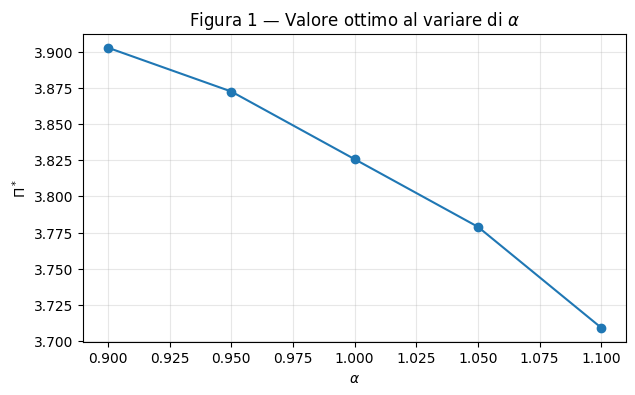

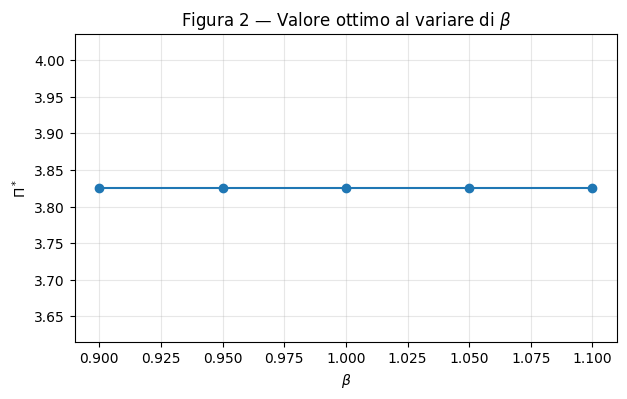

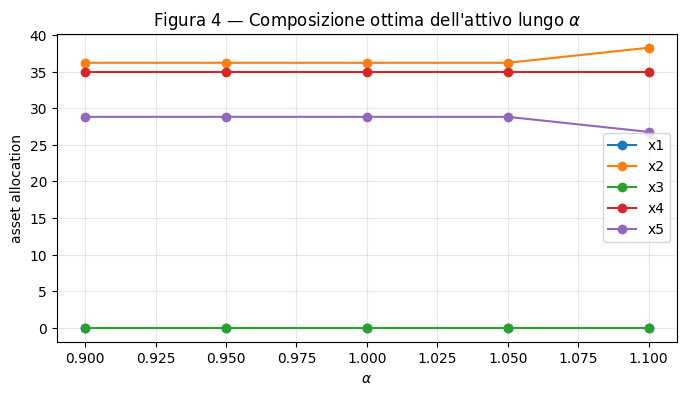

Confronto prima/seconda ondata


,shock,Pi_alpha,Pi_beta,DeltaPi_alpha,DeltaPi_beta
0,0.90,3.902750,3.825698,0.077052,0.0
1,0.95,3.872464,3.825698,0.046766,0.0
2,1.00,3.825698,3.825698,0.000000,0.0
3,1.05,3.778933,3.825698,-0.046766,0.0
4,1.10,3.709183,3.825698,-0.116515,0.0
5,1.15,NaN,NaN,NaN,NaN


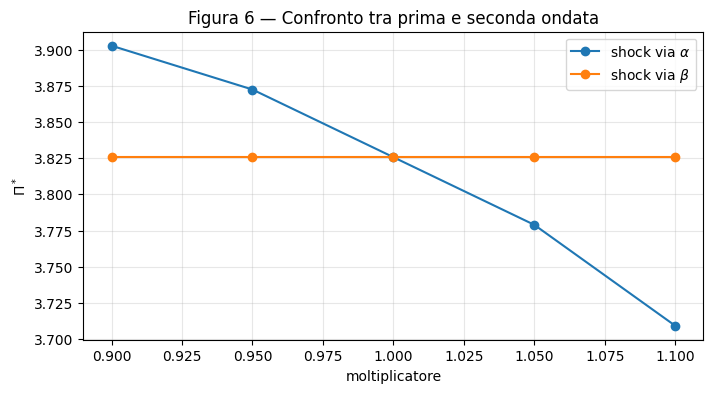

In [3]:
def th_row(o,pname,pval):
    rr={pname:pval,"success":o["success"],"status":o["status"]}
    if not o["success"]: return rr
    rr["Pi"]=o["Pi"]; rr["Delta_Pi"]=o["Pi"]-Pi
    for j in range(5): rr[f"x{j+1}"]=o["x"][j]
    for t in range(4): rr[f"g{t+1}"]=o["g"][t]
    for t in range(3):
        rr[f"u{t+1}"]=o["u"][t]
        rr[f"rho_u{t+1}"]=o["u"][t]/(o["phi"]*u_bar[t])
    rr["legacy_value"]=o["x"][2]+o["x"][3]
    rr["legacy_slack"]=rr["legacy_value"]-L_legacy
    rr["legacy_marginal"]=o["ub_marg"][1]
    rr["x5_slack"]=x5_max-o["x"][4]
    return rr

grid=np.array([0.90,0.95,1.00,1.05,1.10,1.15])
df_a=pd.DataFrame([th_row(solve_th(alpha=float(q)),"alpha",q) for q in grid])
df_b=pd.DataFrame([th_row(solve_th(beta=float(q)),"beta",q) for q in grid])

print("Tabella 2 — Sensitività ad alpha")
display(df_a)
print("Tabella 3 — Sensitività a beta")
display(df_b)

va=df_a[df_a.success]; vb=df_b[df_b.success]

plt.figure(figsize=(7,4))
plt.plot(va["alpha"],va["Pi"],marker="o")
plt.xlabel(r"$\alpha$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 1 — Valore ottimo al variare di $\alpha$")
plt.grid(True,alpha=.3); plt.show()

plt.figure(figsize=(7,4))
plt.plot(vb["beta"],vb["Pi"],marker="o")
plt.xlabel(r"$\beta$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 2 — Valore ottimo al variare di $\beta$")
plt.grid(True,alpha=.3); plt.show()

plt.figure(figsize=(8,4))
for col in ["x1","x2","x3","x4","x5"]:
    plt.plot(va["alpha"],va[col],marker="o",label=col)
plt.xlabel(r"$\alpha$"); plt.ylabel("asset allocation")
plt.title(r"Figura 4 — Composizione ottima dell'attivo lungo $\alpha$")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# confronto omogeneo sulle stesse variazioni relative
cmp=pd.DataFrame({
    "shock":grid,
    "Pi_alpha":df_a["Pi"],
    "Pi_beta":df_b["Pi"],
    "DeltaPi_alpha":df_a["Pi"]-Pi,
    "DeltaPi_beta":df_b["Pi"]-Pi
})
print("Confronto prima/seconda ondata")
display(cmp)

plt.figure(figsize=(8,4))
plt.plot(cmp["shock"],cmp["Pi_alpha"],marker="o",label=r"shock via $\alpha$")
plt.plot(cmp["shock"],cmp["Pi_beta"],marker="o",label=r"shock via $\beta$")
plt.xlabel("moltiplicatore"); plt.ylabel(r"$\Pi^*$")
plt.title("Figura 6 — Confronto tra prima e seconda ondata")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

# Tappa 4 — Sensitività a $\phi$ e confronto complessivo dei driver
**Regime A/B**

**Obiettivo.** Analizzare la capacità disponibile di funding e confrontare i tre driver.

**Input.** Solver parametrico e sensitività ad $\alpha$ e $\beta$.

**Operazioni.**
- $\phi\in\{0.30,0.40,\ldots,1.30\}$ con $\alpha=\beta=1$;
- calcolo dei rapporti $u_t^*/(\phi\bar u_t)$;
- collegamento tra valore, funding, legacy, limite $x_5$ e bounds;
- sintesi comparativa con le due ondate.

**Output.** Tabella 4 e Figure 3 e 5.

**Controllo.** $\phi$ modifica esclusivamente i bounds; capacità disponibile e funding effettivamente utilizzato restano distinti.

**Uso successivo.** Scenario analysis.

Tabella 4 — Sensitività a phi


,phi,success,status,Pi,Delta_Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_value,legacy_slack,legacy_marginal,x5_slack
0,0.3,True,0,3.810154,-0.015544,0.0,37.583333,0.0,35.0,27.416667,0.0,2.786733,7.525667,4.037488,1.200000,1.000000,0.0,0.0,0.0,0.0,35.0,0.0,-0.007943,7.583333
1,0.4,True,0,3.817594,-0.008104,0.0,36.916667,0.0,35.0,28.083333,0.0,2.312867,7.249431,4.026261,1.600000,1.000000,0.0,0.0,0.0,0.0,35.0,0.0,-0.007943,6.916667
2,0.5,True,0,3.825034,-0.000664,0.0,36.250000,0.0,35.0,28.750000,0.0,1.839000,6.973195,4.015034,2.000000,1.000000,0.0,0.0,0.0,0.0,35.0,0.0,-0.007943,6.250000
3,0.6,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.848214,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
4,0.7,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.727041,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
5,0.8,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.636161,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
6,0.9,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.565476,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
7,1.0,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
8,1.1,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.462662,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476
9,1.2,True,0,3.825698,0.000000,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.424107,0.0,0.0,0.0,0.0,35.0,0.0,-0.004887,6.190476


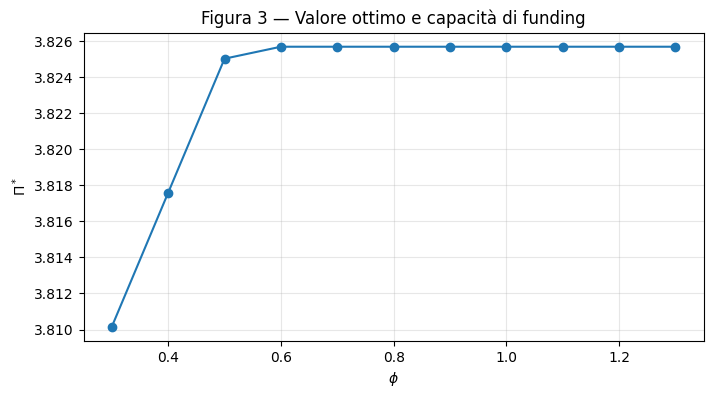

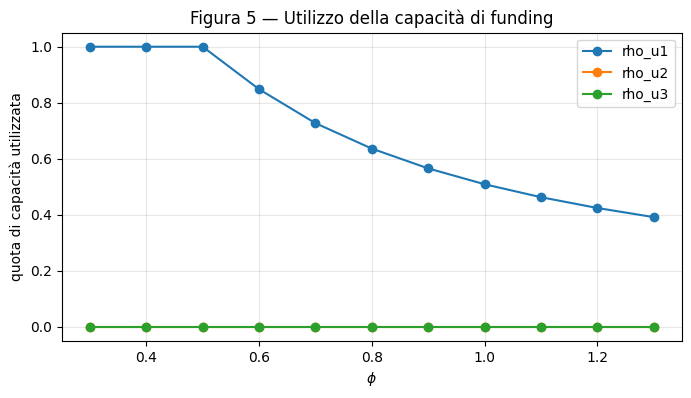

Sintesi comparativa dei driver


,driver,Pi_min,Pi_max,n_fattibili
0,alpha,3.709183,3.902750,5
1,beta,3.825698,3.825698,5
2,phi,3.810154,3.825698,11


Controllo azione esclusiva di phi sui bounds: OK


In [4]:
phi_grid=np.round(np.arange(0.30,1.301,0.10),2)
df_phi=pd.DataFrame([th_row(solve_th(phi=float(q)),"phi",q) for q in phi_grid])

print("Tabella 4 — Sensitività a phi")
display(df_phi)
vp=df_phi[df_phi.success]

plt.figure(figsize=(8,4))
plt.plot(vp["phi"],vp["Pi"],marker="o",label="Pi*")
plt.xlabel(r"$\phi$"); plt.ylabel(r"$\Pi^*$")
plt.title(r"Figura 3 — Valore ottimo e capacità di funding")
plt.grid(True,alpha=.3); plt.show()

plt.figure(figsize=(8,4))
for col in ["rho_u1","rho_u2","rho_u3"]:
    plt.plot(vp["phi"],vp[col],marker="o",label=col)
plt.xlabel(r"$\phi$"); plt.ylabel("quota di capacità utilizzata")
plt.title("Figura 5 — Utilizzo della capacità di funding")
plt.legend(); plt.grid(True,alpha=.3); plt.show()

summary=pd.DataFrame([
    ["alpha",df_a.loc[df_a.success,"Pi"].min(),df_a.loc[df_a.success,"Pi"].max(),df_a.success.sum()],
    ["beta",df_b.loc[df_b.success,"Pi"].min(),df_b.loc[df_b.success,"Pi"].max(),df_b.success.sum()],
    ["phi",df_phi.loc[df_phi.success,"Pi"].min(),df_phi.loc[df_phi.success,"Pi"].max(),df_phi.success.sum()],
],columns=["driver","Pi_min","Pi_max","n_fattibili"])
print("Sintesi comparativa dei driver")
display(summary)

# controllo strutturale: phi non cambia termini noti o coefficienti, solo bounds
f03,Ae03,be03,Au03,bu03,bnd03,_=build_th(phi=0.3)
f13,Ae13,be13,Au13,bu13,bnd13,_=build_th(phi=1.3)
assert np.allclose(f03,f13) and np.allclose(Ae03,Ae13) and np.allclose(be03,be13) and np.allclose(Au03,Au13) and np.allclose(bu03,bu13)
assert bnd03[9:] != bnd13[9:]
print("Controllo azione esclusiva di phi sui bounds: OK")

# Tappa 5 — Scenario analysis
**Regime B**

**Obiettivo.** Analizzare la variazione congiunta dei tre driver.

**Scenari**
- Standard: $(1.00,1.00,1.00)$;
- Mediamente critico: $(1.03,1.03,0.90)$;
- Critico: $(1.06,1.06,0.75)$.

**Output.** Tabella 5 con fattibilità, valore, perdita rispetto allo Standard, soluzione e utilizzo del funding.

**Controllo.** Lo Standard deve riprodurre il benchmark; gli scenari sono deterministici e privi di probabilità.

**Uso successivo.** Controlli conclusivi.

In [5]:
scenari={
    "Standard":(1.00,1.00,1.00),
    "Mediamente critico":(1.03,1.03,0.90),
    "Critico":(1.06,1.06,0.75)
}
rows=[]
for nome,(a,beta,ph) in scenari.items():
    o=solve_th(a,beta,ph)
    row={"scenario":nome,"alpha":a,"beta":beta,"phi":ph,"success":o["success"]}
    if o["success"]:
        row["Pi"]=o["Pi"]
        for j in range(5): row[f"x{j+1}"]=o["x"][j]
        for t in range(4): row[f"g{t+1}"]=o["g"][t]
        for t in range(3):
            row[f"u{t+1}"]=o["u"][t]
            row[f"rho_u{t+1}"]=o["u"][t]/(ph*u_bar[t])
        row["legacy_value"]=o["x"][2]+o["x"][3]
        row["x5"]=o["x"][4]
    rows.append(row)
df_scen=pd.DataFrame(rows)
Pi_std=df_scen.loc[df_scen.scenario=="Standard","Pi"].iloc[0]
df_scen["perdita_vs_Standard"]=np.where(df_scen.success,Pi_std-df_scen["Pi"],np.nan)

print("Tabella 5 — Confronto degli scenari")
display(df_scen)
assert np.isclose(Pi_std,Pi)
print("Scenario Standard = benchmark: OK")

Tabella 5 — Confronto degli scenari


,scenario,alpha,beta,phi,success,Pi,x1,x2,x3,x4,x5,g1,g2,g3,g4,u1,rho_u1,u2,rho_u2,u3,rho_u3,legacy_value,perdita_vs_Standard
0,Standard,1.00,1.00,1.00,True,3.825698,0.0,36.190476,0.0,35.0,28.809524,0.0,1.796690,6.948531,4.014032,2.035714,0.508929,0.0,0.0,0.0,0.0,35.0,0.000000
1,Mediamente critico,1.03,1.03,0.90,True,3.797639,0.0,36.190476,0.0,35.0,28.809524,0.0,0.819410,5.966365,2.065972,2.995714,0.832143,0.0,0.0,0.0,0.0,35.0,0.028059
2,Critico,1.06,1.06,0.75,True,3.751804,0.0,37.783333,0.0,35.0,27.216667,0.0,0.974333,5.644205,0.144737,3.000000,1.000000,0.0,0.0,0.0,0.0,35.0,0.073895


Scenario Standard = benchmark: OK


# Tappa 6 — Controlli conclusivi e predisposizione dell'interpretazione
**Regime A**

**Obiettivo.** Verificare coerenza globale, riproducibilità e autonomia del TakeHome.

**Controlli conclusivi.**
- forma solver coerente con cinque attivi;
- benchmark valido;
- prudenziale, legacy, $x_5\leq35$, funding e non negatività rispettati;
- marginale legacy verificato con la relazione corretta;
- funzione parametrica che replica il benchmark;
- $\alpha$, $\beta$, $\phi$ agiscono solo sugli elementi previsti;
- sensitività $\alpha$ e $\beta$ costruite separatamente;
- costo del funding invariato;
- scenari esatti e Standard uguale al benchmark;
- output costruiti solo da soluzioni valide;
- notebook rieseguibile dall'inizio.

**Limiti interpretativi.**
Il caso è deterministico e stilizzato; i coefficienti non ricostruiscono il bilancio storico di First Republic.

**Uso successivo.** Base quantitativa per il commento autonomo dello studente.

In [6]:
checks={
    "benchmark_success":bool(res.success),
    "eq_residuals_ok":bool(np.max(np.abs(eq_res))<1e-7),
    "inequalities_ok":bool(np.all(sl>=-1e-7)),
    "nonnegative_ok":bool(np.min(z)>=-1e-7),
    "prudential_ok":bool(ell@x<=K+1e-7),
    "legacy_ok":bool(x[2]+x[3]>=L_legacy-1e-7),
    "x5_ok":bool(x[4]<=x5_max+1e-7),
    "legacy_marginal_check_ok":bool(abs(num-m_legacy)<1e-6),
    "parametric_benchmark_ok":bool(np.allclose(solve_th()["z"],z)),
    "alpha_grid_complete":bool(len(df_a)==6),
    "beta_grid_complete":bool(len(df_b)==6),
    "phi_grid_complete":bool(len(df_phi)==11),
    "scenarios_complete":bool(len(df_scen)==3),
    "standard_equals_benchmark":bool(np.isclose(Pi_std,Pi))
}
display(pd.DataFrame({"controllo":list(checks.keys()),"esito":list(checks.values())}))
assert all(checks.values())
print("Tutti i controlli conclusivi: OK")

,controllo,esito
0,benchmark_success,True
1,eq_residuals_ok,True
2,inequalities_ok,True
3,nonnegative_ok,True
4,prudential_ok,True
5,legacy_ok,True
6,x5_ok,True
7,legacy_marginal_check_ok,True
8,parametric_benchmark_ok,True
9,alpha_grid_complete,True


Tutti i controlli conclusivi: OK


# Interpretazione finanziaria finale — spazio dello studente

Da completare autonomamente sulla base degli output già validati.

Il commento finale deve discutere almeno:
1. differenze strutturali rispetto al Caso Aula;
2. ruolo del vincolo legacy e, quando rilevante, del limite su $x_5$;
3. differenze tra shock iniziale e shock terminale;
4. ruolo della capacità di funding;
5. collegamento tra soluzione e vincoli/bounds attivi;
6. differenza tra sensitività univariate e scenario analysis;
7. limiti del modello e distinzione rispetto ai fatti storici di First Republic Bank.